# Clinical outcome data exploration

## Purpose

Initial exploration of longitudinal clinical response classifications
for patients from the ENEST1st and NordCML007 trials.

The supplied clinical data contain ELN response classifications at
months 3, 6, 9, and 12:

- Favorable
- Warning
- Unfavorable
- Missing (NA)

The classifications were derived from BCR::ABL1 IS measurements by
the supplied R preprocessing script.

Note: M09 is not an ELN milestone. In the supplied preprocessing code,
the M12 thresholds were used to categorize M09 values.

## Questions

1. How many patients are available in each trial?
2. How much clinical outcome data are missing?
3. What is the distribution of response categories at each time point?
4. How do individual patients' classifications change over time?
5. How balanced are the possible ML target classes?
6. Which patients have complete longitudinal clinical information?

In [29]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

In [ ]:
# Paths
PROJECT_ROOT = Path.cwd().parents[1]
DATA_DIR = PROJECT_ROOT / "data"

# Analysis constants
TIMEPOINTS = ["ELN_M03", "ELN_M06", "ELN_M09", "ELN_M12"]
CATEGORY_ORDER = ["Favorable", "Warning", "Unfavorable"]

# Load clinical data
enest = pd.read_csv(DATA_DIR / "BCRABL1IS_ENEST.csv", sep=";")
n007 = pd.read_csv(DATA_DIR / "BCRABL1IS_N007.csv", sep=";")

# Add trial information
enest["trial"] = "ENEST1st"
n007["trial"] = "N007"

# Combine datasets
clinical = pd.concat([enest, n007], ignore_index=True)

#IDs may now not be unique (same id used for different patients in the different trials)
clinical["sample_patient_id"] = (
    clinical["trial"] + "_" + clinical["patient"].astype(str)
)

clinical.head()

,patient,ELN_M03,ELN_M06,ELN_M09,ELN_M12,trial,sample_patient_id
0,42,Favorable,Warning,Warning,Warning,ENEST1st,ENEST1st_42
1,41,Favorable,Favorable,Favorable,Favorable,ENEST1st,ENEST1st_41
2,40,Favorable,Warning,Warning,Warning,ENEST1st,ENEST1st_40
3,39,Favorable,Favorable,Favorable,Favorable,ENEST1st,ENEST1st_39
4,38,Favorable,Favorable,Favorable,Favorable,ENEST1st,ENEST1st_38


## Dataset overview

First, inspect the number of records, columns, patient identifiers, response categories, and duplicates.

In [32]:
print(f"ENEST1st: {len(enest)} clinical patients")
print(f"N007: {len(n007)} clinical patients")
print(f"Combined: {len(clinical)} clinical records")

display(clinical.head())

print("\nObserved response categories:")
for column in TIMEPOINTS:
    print(f"{column}: {clinical[column].dropna().unique()}")

print("\nDuplicate patient IDs within each trial:")
display(
    clinical.groupby("trial")["patient"]
    .apply(lambda x: x.duplicated().sum())
)

ENEST1st: 52 clinical patients
N007: 38 clinical patients
Combined: 90 clinical records


,patient,ELN_M03,ELN_M06,ELN_M09,ELN_M12,trial
0,42,Favorable,Warning,Warning,Warning,ENEST1st
1,41,Favorable,Favorable,Favorable,Favorable,ENEST1st
2,40,Favorable,Warning,Warning,Warning,ENEST1st
3,39,Favorable,Favorable,Favorable,Favorable,ENEST1st
4,38,Favorable,Favorable,Favorable,Favorable,ENEST1st



Observed response categories:
ELN_M03: ['Favorable' 'Warning']
ELN_M06: ['Warning' 'Favorable' 'Unfavorable']
ELN_M09: ['Warning' 'Favorable' 'Unfavorable']
ELN_M12: ['Warning' 'Favorable' 'Unfavorable']

Duplicate patient IDs within each trial:


trial
ENEST1st    0
N007        0
Name: patient, dtype: int64

## Missing data

Patients with clinical records may not have measurements at every time point. Missing clinical data may affect which patients can be used for a particular prediction target.

In [33]:
missing_summary = (
    clinical
    .groupby("trial")[TIMEPOINTS]
    .agg(lambda x: x.isna().sum())
)

display(missing_summary)

,ELN_M03,ELN_M06,ELN_M09,ELN_M12
trial,,,,
ENEST1st,3,1,1,1
N007,0,1,2,1


In [35]:
clinical["complete_followup"] = clinical[TIMEPOINTS].notna().all(axis=1)

complete_summary = (
    clinical
    .groupby("trial")["complete_followup"]
    .value_counts()
    .unstack(fill_value=0)
)

display(complete_summary)

complete_followup,False,True
trial,,
ENEST1st,3,49
N007,2,36


## Response distributions

The following plot shows how many patients fall into each response category at each time point.

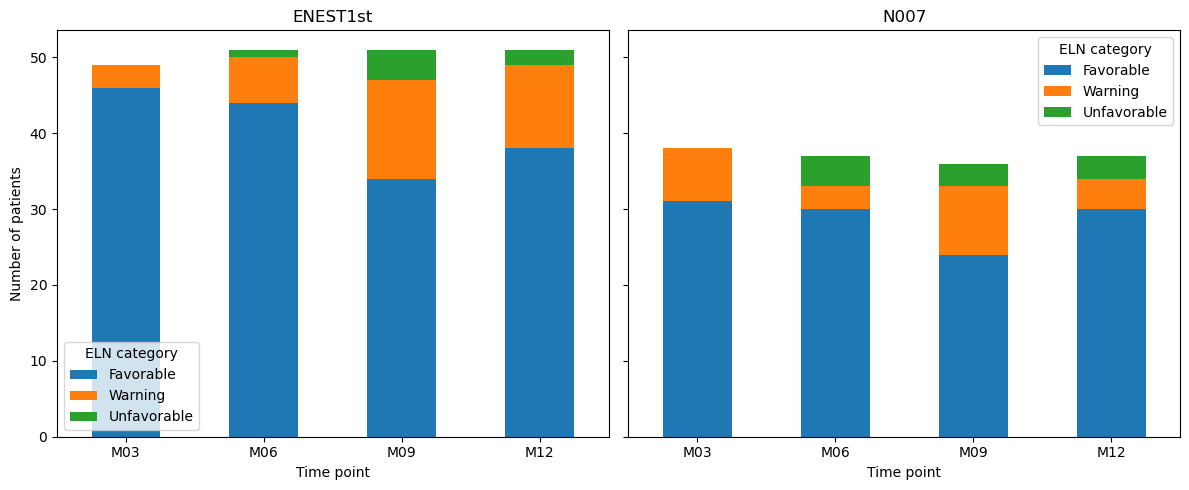

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)

for ax, (trial, df) in zip(axes, clinical.groupby("trial")):

    counts = pd.DataFrame({
        tp: df[tp].value_counts().reindex(CATEGORY_ORDER, fill_value=0)
        for tp in TIMEPOINTS
    }).T

    counts.plot(
        kind="bar",
        stacked=True,
        ax=ax
    )

    ax.set_title(trial)
    ax.set_xlabel("Time point")
    ax.set_ylabel("Number of patients")
    ax.set_xticklabels(["M03", "M06", "M09", "M12"], rotation=0)
    ax.legend(title="ELN category")

plt.tight_layout()
plt.show()

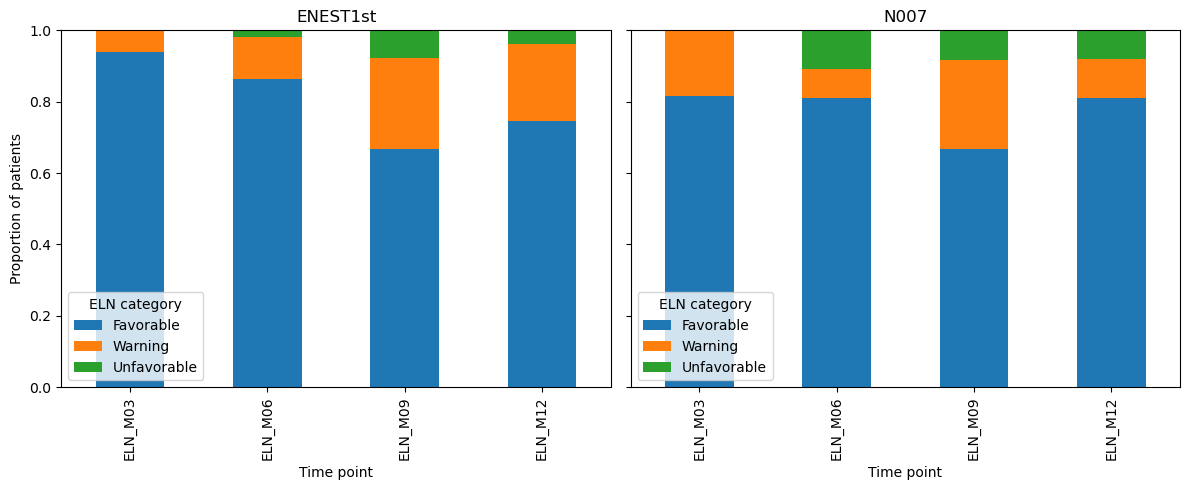

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)

for ax, (trial, df) in zip(axes, clinical.groupby("trial")):

    proportions = pd.DataFrame({
        tp: (
            df[tp]
            .value_counts(normalize=True)
            .reindex(CATEGORY_ORDER, fill_value=0)
        )
        for tp in TIMEPOINTS
    })

    proportions.T.plot(
        kind="bar",
        stacked=True,
        ax=ax
    )

    ax.set_title(trial)
    ax.set_xlabel("Time point")
    ax.set_ylabel("Proportion of patients")
    ax.set_ylim(0, 1)
    ax.legend(title="ELN category")

plt.tight_layout()
plt.show()

## Individual response trajectories

A patient may change response classification during follow-up.
Visualizing patients across time therefore provides information that is lost when considering each time point independently.

The numerical encoding below is used **only for visualization**:

- Favorable = 0
- Warning = 1
- Unfavorable = 2

It should not be interpreted as a numerical clinical response scale.

/var/folders/gq/xt5h1r3x3xd__6v2t4kfr3br0000gn/T/ipykernel_12440/3241443358.py:12: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  .replace(ELN_TO_NUMERIC)


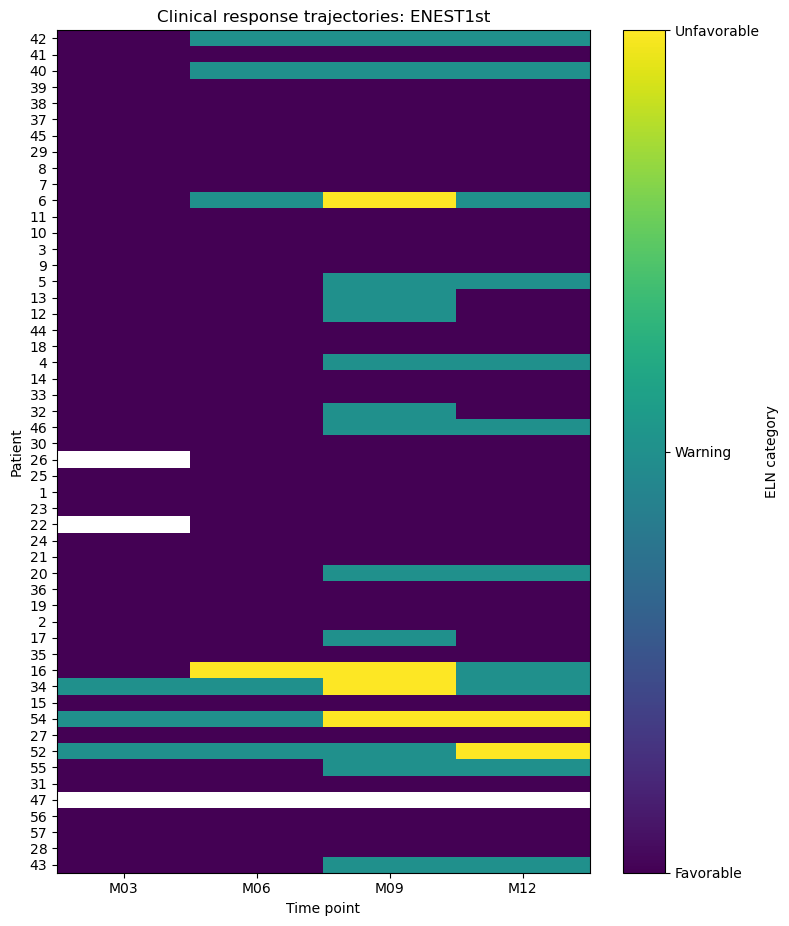

/var/folders/gq/xt5h1r3x3xd__6v2t4kfr3br0000gn/T/ipykernel_12440/3241443358.py:12: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  .replace(ELN_TO_NUMERIC)


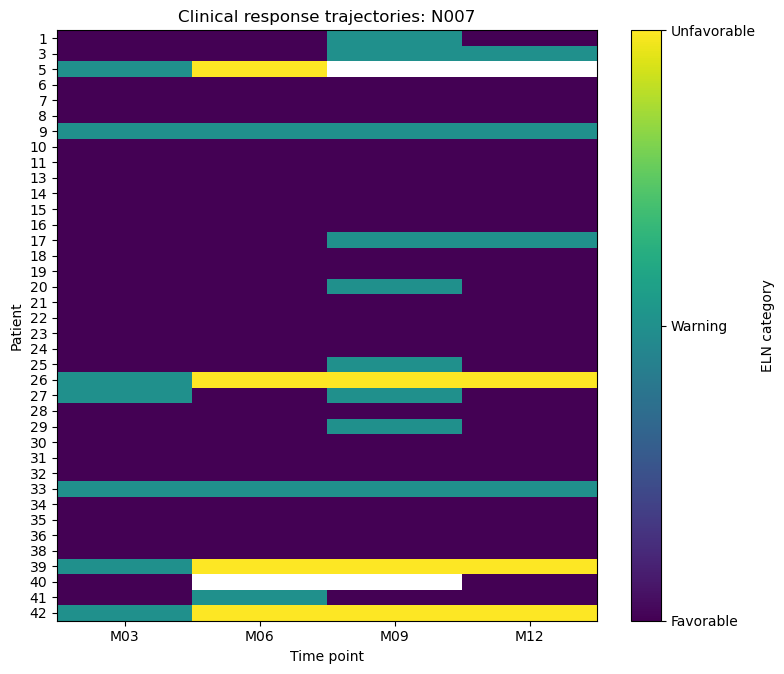

In [37]:
ELN_TO_NUMERIC = {
    "Favorable": 0,
    "Warning": 1,
    "Unfavorable": 2
}

for trial, df in clinical.groupby("trial"):

    trajectory_data = (
        df
        .set_index("patient")[TIMEPOINTS]
        .replace(ELN_TO_NUMERIC)
        .astype(float)
    )

    fig, ax = plt.subplots(
        figsize=(8, max(5, len(trajectory_data) * 0.18))
    )

    image = ax.imshow(
        trajectory_data,
        aspect="auto",
        interpolation="nearest"
    )

    ax.set_title(f"Clinical response trajectories: {trial}")
    ax.set_xlabel("Time point")
    ax.set_ylabel("Patient")

    ax.set_xticks(range(len(TIMEPOINTS)))
    ax.set_xticklabels(["M03", "M06", "M09", "M12"])

    ax.set_yticks(range(len(trajectory_data)))
    ax.set_yticklabels(trajectory_data.index)

    colorbar = fig.colorbar(image, ax=ax)
    colorbar.set_ticks([0, 1, 2])
    colorbar.set_ticklabels(ELN_ORDER)
    colorbar.set_label("ELN category")

    plt.tight_layout()
    plt.show()

## Initial observations

_To be completed after inspecting the outputs above._

### Dataset

- ENEST1st is a bit bigger than N007 with 52 vs. 38 patients
- Around 5 percent of the data is missing, 85 out of 90 profiles are complete
- Class balance: Favorable is by far the most common class lable
- Common longitudinal patterns: Around half of all trajectories are favorable throughout

### Implications for machine learning

- The eventual prediction target still needs to be defined.
- Clinical class imbalance may be relevant depending on the chosen target.
- Clinical patient records still need to be matched to patients with
  mass-cytometry samples.

### Questions for supervision

- [ ] Class imbalance problematic?
- [ ] Trajectory imbalance problematic?
- [ ] What is the prediction target, what are we using trying to predict outcome?
- [ ] Should ENEST1st and N007 ultimately be analyzed together?
- [ ] How should patients without cytometry samples be handled?